# PyTorch Fundamentals: From Tensors to a Trained Neural Network


---
# Chapter 0. Setup 
**Colab:** *Runtime → Change runtime type → T4 GPU*, then run the cell below. It should print `device: cuda`.
**Own machine:** install `torch`, `torchvision` and `matplotlib` 

In [ ]:
import math, platform, random, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn                 
import torch.nn.functional as F       
import torchvision                    
import matplotlib.pyplot as plt

_ver = tuple(int(p) for p in torch.__version__.split("+")[0].split(".")[:2])


FAST_DEV_RUN = False   # True = tiny data and 1 epoch everywhere: a quick smoke test of the whole notebook
RUN_SOLUTIONS = False  # True = also execute the hidden exercise solutions during "Run all" (slower)
DATA_DIR = Path("./data")
DATA_DIR.mkdir(exist_ok=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

def sync(dev=None) -> None:
    # GPU work is asynchronous: wait until it has finished (needed before reading a clock).
    dev = dev or device
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()

def set_seed(seed: int = 0) -> None:
    # Make random numbers repeatable
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)            

def n_epochs(full: int) -> int:
    # Number of training epochs: `full` normally, 1 in smoke-test mode.
    return 1 if FAST_DEV_RUN else full

def maybe_subset(ds, n: int = 512):
    # The whole dataset normally; only its first n items in smoke-test mode.
    return torch.utils.data.Subset(ds, range(min(n, len(ds)))) if FAST_DEV_RUN else ds

RESULTS = {}           # the numbers of measurement, collected as you go and summarized at the end
def record(name, value):
    RESULTS[name] = value
    print(f"recorded  {name}: {value:.4f}")

print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
set_seed(0)

---
# Chapter 1. Tensors

**Goal**: Create tensors with the right dtype; read and change shapes; index, broadcast and reduce; multiply matrices; use the GPU.

A **tensor** is an n-dimensional array of numbers of one type. The API is close to NumPy. PyTorch adds three things: a **device** (CPU or GPU), **automatic differentiation** (Chapter 2), and **16-bit number formats** for speed.

| Rank (`ndim`) | Example shape | Typical meaning |
| --- | --- | --- |
| 0 | `()` | a loss value |
| 1 | `(10,)` | a bias vector; the labels of 10 examples |
| 2 | `(64, 784)` | 64 flattened 28×28 images, **one row per example** |
| 4 | `(64, 3, 32, 32)` | 64 color images, **(N, C, H, W)** = batch, channels, height, width |

**Convention:** dimension 0 is the **batch**. Most bugs are shape bugs, so **print shapes** often.

## 1.1 Creating tensors

In [ ]:
a = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])          # from a nested Python list
print(a)
print("shape:", a.shape, "| ndim:", a.ndim, "| numel:", a.numel())
print("dtype:", a.dtype, "| device:", a.device)

`a.shape` behaves like a tuple; `a.numel()` is the number of elements. The common **factory functions**:

In [ ]:
print(torch.zeros(2, 3))                    # all zeros, shape (2, 3)
print(torch.ones(2, 3))
print(torch.full((2, 2), 7.0))              # every entry 7.0
print(torch.arange(0, 10, 2))               # 0, 2, 4, 6, 8 : like range(), the end is excluded
print(torch.linspace(0, 1, 5))              # 5 evenly spaced points, both ends included
print(torch.eye(3))                         # 3x3 identity matrix
print(torch.rand(2, 3))                     # uniform random numbers in [0, 1)
print(torch.randn(2, 3))                    # standard normal N(0, 1): used to initialize weights
print(torch.randint(0, 10, (5,)))           # 5 random integers in [0, 10): fake class labels
print(torch.zeros_like(a))                  # same shape, dtype and device as `a`

### dtypes
| dtype | Alias | Use |
| --- | --- | --- |
| `torch.float32` | `torch.float` | inputs, weights, activations, losses (**PyTorch's default**) |
| `torch.int64` | `torch.long` | class labels and indices |
| `torch.bool` | | masks such as `x > 0` |
| `torch.float64` | `torch.double` | high-precision checks (**NumPy's default**) |

NumPy data is `float64`, PyTorch layers are `float32`. Mixing them is the classic first-week error:

In [ ]:
x_np = np.random.rand(4, 3)                  # NumPy: float64
layer = nn.Linear(3, 2)                      # PyTorch layer: float32 weights
print("numpy dtype:", x_np.dtype, "| layer dtype:", layer.weight.dtype)

try:
    layer(torch.from_numpy(x_np))            # float64 input into a float32 layer
except RuntimeError as e:
    print("RuntimeError:", e)

x = torch.from_numpy(x_np).float()           # the fix: convert ONCE, where NumPy data enters PyTorch
print("works:", layer(x).shape)

Convert with `.float()`, `.long()`, `.bool()` or `.to(dtype)`. Note that `/` always returns a float (`torch.tensor(7) / 2` is `3.5`), while `//` is integer division.

**Copy or share?** `torch.tensor(array)` **copies**. `torch.from_numpy(array)` and `tensor.numpy()` **share memory** on the CPU: changing one changes the other.

In [ ]:
arr = np.zeros(3)
shared = torch.from_numpy(arr)
copied = torch.tensor(arr)
arr[0] = 42.0                    # modify the NumPy array
print("shared:", shared)         # sees the change
print("copied:", copied)         # does not

## 1.2 Changing shape
Reshaping preserves element values but may return a view **or a copy**, depending on strides. Ordinary **contiguous** tensors use row-major layout (last index changes fastest); transposed/permuted tensors need not be contiguous. A shape is not a guarantee of memory layout.

| Operation | What it does | Typical use |
| --- | --- | --- |
| `x.reshape(2, -1)` | same elements, new shape; `-1` = "work it out" | general |
| `x.flatten(start_dim=1)` | merge all dims from `start_dim` on | `(N, 1, 28, 28) → (N, 784)` |
| `x.unsqueeze(d)` / `x.squeeze(d)` | insert / remove a size-1 dim at `d` | add a batch dim; `(N, 1) → (N,)` |
| `x.permute(…)` | reorder dims | `(H, W, C) → (C, H, W)` |
| `x.T`, `x.transpose(i, j)` | swap two dims | matrix transpose |


In [ ]:
x = torch.arange(12)                  # tensor([0, 1, ..., 11]), shape (12,)
# TODO: reshape x to (3, 4). Hint: rows are filled in order: [0..3], [4..7], [8..11]
print(____)
# TODO: reshape x to 2 rows and let PyTorch infer the other size. 
print(____.shape)
# TODO: reshape x to (2, 3, 2) and print its shape
print(____.shape)

imgs = torch.randn(8, 1, 28, 28)      # a batch of 8 grayscale images, (N, C, H, W)
# TODO: flatten each image but keep the batch dim N. Hint: flatten(start_dim=...)
print("flatten(start_dim=1):", ____.shape)
# TODO: call flatten() with no arguments. Hint: it merges the batch too: usually a bug!
print("flatten():           ", ____.shape)

In [ ]:
one_image = torch.randn(1, 28, 28)                 # a single image, (C, H, W)
# TODO: add a batch dimension at position 0. Hint: models always expect a batch dimension
batch = ____
print("unsqueeze(0):", one_image.shape, "->", batch.shape)
# TODO: get the same result using None indexing. Hint: one_image[...]
print("same thing with None indexing:", ____.shape)

preds = torch.randn(5, 1)                          # e.g. a regression model's output
# TODO: remove the size-1 dim, (5, 1) -> (5,). Hint: which dim index has size 1?
print("squeeze(1):", preds.shape, "->", ____.shape)

photo = torch.rand(32, 32, 3)                      # how image files are stored: (H, W, C)
# TODO: move channels first, (H, W, C) -> (C, H, W). Hint: pass the OLD dim indices in the NEW order
chw = ____
print("permute(2, 0, 1):", photo.shape, "->", chw.shape)

**NOTE:** **`reshape` is not `permute`.** Both turn `(32, 32, 3)` into `(3, 32, 32)`, but only `permute` keeps each pixel's colors together. `reshape` re-cuts the flat sequence and scrambles the image:

In [ ]:
# A 2x2 "image" with 3 channels, stored (H, W, C). The value encodes the channel: 0.x = R, 1.x = G, 2.x = B
img = torch.tensor([[[0.0, 1.0, 2.0], [0.1, 1.1, 2.1]],
                    [[0.2, 1.2, 2.2], [0.3, 1.3, 2.3]]])
# TODO: convert (H, W, C) -> (C, H, W) with permute, then take channel 0 with [0]
print("permute -> channel 0 should hold only 0.x values:\n", ____)
# TODO: convert to the same target shape (3, 2, 2) with reshape, then take channel 0 with [0]
print("reshape -> channel 0 is a mixture (wrong):\n", ____)

## 1.3 Indexing
Indexing works like NumPy: one index or slice per dimension.

In [ ]:
x = torch.arange(12).reshape(3, 4)
print(x)
# TODO: index with the expression described in each comment (a row, one element, columns, slices, a list of rows)
print("x[1]        ->", ____)              # row 1 (the second row)
print("x[1, 2]     ->", ____)           # a 0-d tensor; use .item() to get a Python number
print("x[:, 2]     ->", ____)           # column 2, from every row
print("x[:, -1]    ->", ____)          # the last column
print("x[0:2, 1:3] ->\n", ____)     # rows 0-1, columns 1-2
print("x[[0, 2]]   ->\n", ____)       # a list of indices picks those rows

**Boolean masks** select the elements where a condition holds:

In [ ]:
x = torch.arange(12).reshape(3, 4)
# TODO: boolean tensor: True where x > 5
mask = ____
print(mask)
# TODO: select the elements with the mask
print("x[mask]:", ____)              # a 1-D tensor of the selected values
# TODO: True counts as 1 when summed
print("how many > 5:", ____)

y = x.clone()                           # clone() makes an independent copy
# TODO: mask for the even entries
y[____] = -1                      # assign through a mask
print(y)

**One entry per row.** To pick, for each example, the probability of its **correct** class, index with two equal-length tensors: one for rows, one for columns.

In [ ]:
probs = torch.tensor([[0.7, 0.2, 0.1],
                      [0.1, 0.8, 0.1],
                      [0.3, 0.3, 0.4],
                      [0.5, 0.4, 0.1]])
labels = torch.tensor([0, 1, 0, 1])                 # correct class of each example

# TODO: pick probs[i, labels[i]] for every row i: one index tensor for rows, one for columns
p_correct = ____          # rows 0,1,2,3 paired with columns 0,1,0,1
print("probability of the correct class:", p_correct)   # tensor([0.7, 0.8, 0.3, 0.4])
# TODO: negative mean of the log of p_correct
print("cross-entropy by hand:", ____)

## 1.4 Broadcasting
An elementwise operation on tensors of **different shapes** stretches size-1 dimensions so the shapes match, without copying the inputs.

**Rule:** align the shapes **from the right**. Each pair of sizes must be equal, or one of them must be 1. A missing dimension counts as 1.

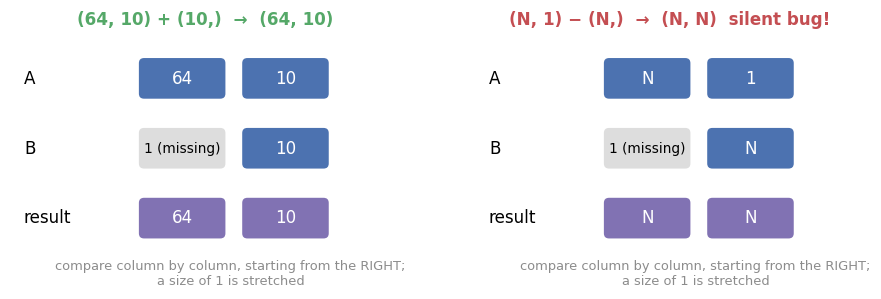

A bias is added by broadcasting: `X @ W.T + b` adds `b` of shape `(out,)` to every row of an `(N, out)` matrix.

In [ ]:
X = torch.randn(5, 3)                                 # 5 examples, 3 features
b = torch.tensor([10.0, 20.0, 30.0])                  # one value per feature
print((X + b).shape)                                  # (5, 3): b added to every row

# Standardize every feature (column) to mean 0, std 1.
# TODO: mean and std of each column; keep the reduced dim so the shape is (1, 3)
mean = ____                    # (1, 3): one mean per column (see 1.5)
std = ____                      # (1, 3); note: divides by N-1 (NumPy's np.std divides by N)
# TODO: subtract the mean and divide by the std; broadcasting does the rest
Xs = ____                                 # (5, 3) op (1, 3) -> (5, 3)
print("column means:", Xs.mean(dim=0))                # approx. 0
print("column stds: ", Xs.std(dim=0))                 # approx. 1

# The "outer" pattern: (3, 1) op (1, 4) -> (3, 4), every combination
rows = torch.tensor([[1.0], [2.0], [3.0]])
cols = torch.tensor([[10.0, 20.0, 30.0, 40.0]])
# TODO: "outer" pattern: (3, 1) op (1, 4) -> (3, 4)
print(____)

**NOTE:** **The `(N, 1)` vs `(N,)` bug.** A regression model outputs `(N, 1)`; targets loaded from a file are often `(N,)`. Their difference broadcasts to `(N, N)`: every prediction is compared with every target. Training runs, the loss is finite, and the model learns almost nothing.


In [ ]:
N = 4
pred = torch.randn(N, 1)       # model output: (N, 1)
y = torch.randn(N)             # targets:      (N,)
print("pred - y has shape", (pred - y).shape)            # (4, 4), not (4,)!

wrong = ((pred - y) ** 2).mean()                         # silently wrong
# TODO: make pred the same shape as y before subtracting
right = ((____ - y) ** 2).mean()              # make the shapes equal first
print(f"wrong loss: {wrong:.3f}   right loss: {right:.3f}")

**Note:** assert shapes where data meets the model or the loss, e.g. `assert pred.shape == y.shape`.

## 1.5 Reductions and `dim`
Functions `sum`, `mean`, `max`, `std`, `argmax` collapse a dimension. **The `dim` you name is the one that disappears.** For a `(examples, features)` matrix, `x.sum(dim=0)` gives one value per feature and `x.sum(dim=1)` one value per example. `keepdim=True` keeps it with size 1, so the result still broadcasts against `x`.

In [ ]:
x = torch.tensor([[1.0, 5.0, 3.0],
                  [4.0, 2.0, 6.0]])               # shape (2, 3)
print("x.sum()              =", x.sum())               # everything -> a scalar
# TODO: choose dim so the result has the shape given in each comment
print("x.sum(dim=0)         =", x.sum(dim=____))          # (3,): one per column
print("x.sum(dim=1)         =", x.sum(dim=____))          # (2,): one per row
print("x.sum(dim=1, keepdim=True).shape =", x.sum(dim=1, keepdim=____).shape)   # (2, 1)

values, indices = x.max(dim=____)                     # max along a dim returns BOTH
print("max of each row:", values, "found at column", indices)
print("argmax(dim=1):  ", x.argmax(dim=____))         # how logits become predicted classes

From logits to accuracy, a pattern you will write in every classification project:

In [ ]:
logits = torch.tensor([[2.0, 0.5, -1.0],     # model scores, shape (N=4, C=3)
                       [0.1, 0.2,  3.0],
                       [1.0, 2.0,  0.0],
                       [0.3, 0.1,  0.2]])
labels = torch.tensor([0, 2, 0, 0])

# TODO: index of the highest score in each row
predicted = ____              # (4,): the class with the highest score in each row
# TODO: elementwise comparison
correct = ____               # (4,) booleans
print("predicted:", predicted, "| correct:", correct)
# TODO: booleans -> float, then average
print("accuracy:", ____)   # bool -> float, then average

## 1.6 Combining and selecting

| Function | What it does |
| --- | --- |
| `torch.cat([a, b], dim=d)` | join along an **existing** dim |
| `torch.stack([a, b], dim=d)` | join equal-shape tensors along a **new** dim |
| `torch.where(cond, a, b)` | elementwise: `a` where `cond`, else `b` |
| `x.masked_fill(mask, v)` | copy of `x` with `v` where `mask` is true |
| `x.topk(k, dim)` / `x.argsort(dim)` | the `k` largest values and their indices / the sorting order |


In [ ]:
a, b = torch.zeros(2, 3), torch.ones(4, 3)
# TODO: choose dim so the result has the shape given in each comment; stack builds a batch from a list
print("cat dim=0:  ", torch.cat([a, b], dim=____).shape)                 # (6, 3): more rows
print("cat dim=1:  ", torch.cat([a, torch.ones(2, 5)], dim=____).shape)  # (2, 8): more columns
p, q = torch.zeros(2, 3), torch.ones(2, 3)
print("stack dim=0:", torch.stack([p, q], dim=____).shape)              # (2, 2, 3): a new leading dimension
print("stack dim=2:", torch.stack([p, q], dim=____).shape)              # (2, 3, 2): a new last dimension

# stack is what a DataLoader does to build a batch: 4 examples of shape (1, 28, 28) -> (4, 1, 28, 28)
examples = [torch.randn(1, 28, 28) for _ in range(4)]
print("a batch:    ", ____.shape)

In [ ]:
x = torch.tensor([[-2.0, 0.5, 3.0],
                  [1.0, -0.5, -4.0]])
# TODO: ReLU: keep x where it is positive, else 0
print("where(x > 0, x, 0):\n", torch.where(____, x, 0.0))      # ReLU written by hand
# TODO: mask of the entries to overwrite
print("masked_fill(x < 0, -1):\n", x.masked_fill(____, -1.0))

# A very common pattern: forbid some options by setting their logits to -inf before a softmax
logits = torch.tensor([[2.0, 1.0, 0.5, 3.0]])
allowed = torch.tensor([[True, True, True, False]])                  # option 3 is not allowed here
# TODO: fill where the option is NOT allowed
print("softmax with option 3 masked out:", torch.softmax(logits.masked_fill(____, float("-inf")), dim=1))

In [ ]:
scores = torch.tensor([[0.1, 0.5, 0.3, 0.9, 0.2],
                       [0.8, 0.1, 0.6, 0.0, 0.4]])
values, indices = ____            # the 3 best classes of each row, best first
print("top-3 values: ", values)
print("top-3 classes:", indices)
print("full ranking: ", scores.argsort(dim=1, descending=____))

labels = torch.tensor([1, 4])
# TODO: compare each of the 3 predicted classes with the label via broadcasting (N, 3) vs (N, 1), then reduce over dim=1
in_top3 = ____  # broadcasting (N, 3) == (N, 1)
print("top-3 accuracy:", in_top3.float().mean().item())   # common on ImageNet-style benchmarks

## 1.7 Elementwise vs matrix multiplication
- `A * B`: elementwise (Hadamard) product, with broadcasting.
- `A @ B`: matrix product, `(n, k) @ (k, m) → (n, m)`. With more than 2 dims, the leading dims are a batch.

`nn.Linear(in, out)` stores `W` with shape **`(out, in)`** and computes `x @ W.T + b`:

In [ ]:
lin = nn.Linear(3, 2)                       # 3 inputs -> 2 outputs
x = torch.randn(5, 3)                       # a batch of 5 examples
print("weight:", lin.weight.shape, "| bias:", lin.bias.shape)    # (2, 3) and (2,)

# TODO: reproduce nn.Linear: x @ W.T + b
by_hand = ____       # (5,3) @ (3,2) -> (5,2), plus (2,) broadcast to every row
print("output:", lin(x).shape, "| matches by hand:", torch.allclose(lin(x), by_hand))

A = torch.randn(10, 4, 5)                   # a batch of 10 matrices, each 4x5
B = torch.randn(10, 5, 6)
# TODO: batched matrix product
print("batched matmul:", (____).shape)     # (10, 4, 6)

Compare floats with `torch.allclose`, never `==`: the same maths computed in a different order differs in the last bits.

## 1.8 Devices: CPU and GPU
1. Move with `.to(device)`.
2. All tensors in one operation must be on the **same device**, otherwise: *"Expected all tensors to be on the same device"*.
3. CPU ↔ GPU copies are slow. Keep work on the GPU; bring back a number with `.item()` or a tensor with `.cpu()`.

In [ ]:
x_cpu = torch.randn(3, 3)
# TODO: move x_cpu to the device
x_dev = ____
print("x_dev lives on:", x_dev.device)

if device.type != "cpu":
    try:
        x_cpu + x_dev                               # mixed devices
    except RuntimeError as e:
        print("RuntimeError:", str(e)[:95], "...")

y = torch.zeros(3, 3, ____)                # or create a tensor directly on the device
loss = ((x_dev - y) ** 2).mean()
print("a Python float:", ____)               # 1-element tensor -> Python number
# TODO: GPU tensors must come to the CPU first
print("a NumPy array:\n", ____)      # GPU tensors must come to the CPU before .numpy()

## 1.9 In-place operations
Methods ending in `_` (`x.add_(1)`, `x.zero_()`), as well as `x += 1` and `x[idx] = v`, modify a tensor **in place**. They save memory but can destroy values autograd needs (Chapter 2). Default to the out-of-place versions.

In [ ]:
x = torch.ones(3)
# TODO: out-of-place add of 1
y = ____        # new tensor; x unchanged
print("after add: ", x, y)
# TODO: in-place add of 1
____           # x itself is modified
print("after add_:", x)

### Key takeaways
- A tensor has a **shape**, a **dtype** and a **device**; most errors are a mismatch in one of them.
- Continuous data `float32`, labels `int64`; convert NumPy data with `.float()`.
- In a reduction, the `dim` you name disappears; `keepdim=True` keeps it for broadcasting.
- Broadcasting aligns from the right: `(N, 1)` with `(N,)` silently gives `(N, N)`.
- `nn.Linear` computes `x @ W.T + b` with `W` of shape `(out, in)`.

---
# Chapter 2. Autograd: backpropagation, done for you

Compute gradients with `backward()`; explain what autograd records; avoid the accumulation and memory-leak pitfalls; switch autograd off; run gradient descent with plain tensors.

**Autograd** is PyTorch's implementation of backpropagation. Operations on tensors with `requires_grad=True` are recorded; `loss.backward()` walks that record backwards with the chain rule and stores each gradient in the `.grad` attribute of the tensors you asked about.

## 2.1 A hand calculation, checked by autograd
One input, one sigmoid hidden unit, one sigmoid output, squared error:

$$z_1 = w_1 x + b_1,\quad a_1 = \sigma(z_1),\quad z_2 = w_2 a_1 + b_2,\quad a_2 = \sigma(z_2),\quad L = \tfrac12 (a_2 - y)^2$$

with $w_1 = 0.5,\ b_1 = 0.1,\ w_2 = 0.8,\ b_2 = -0.3,\ x = 2,\ y = 1$ and $\sigma'(z) = \sigma(z)(1 - \sigma(z))$.

**Forward:** $z_1 = 1.1$, $a_1 = 0.7503$, $z_2 = 0.3002$, $a_2 = 0.5745$, $L = 0.0905$.

**Backward:**

| Quantity | Formula | Value |
| --- | --- | --- |
| $\delta_2 = \partial L/\partial z_2$ | $(a_2 - y)\, a_2 (1 - a_2)$ | $-0.1040$ |
| $\partial L/\partial w_2$, $\partial L/\partial b_2$ | $\delta_2 a_1$, $\delta_2$ | $-0.0780$, $-0.1040$ |
| $\delta_1 = \partial L/\partial z_1$ | $\delta_2 w_2\, a_1 (1 - a_1)$ | $-0.0156$ |
| $\partial L/\partial w_1$, $\partial L/\partial b_1$ | $\delta_1 x$, $\delta_1$ | $-0.0312$, $-0.0156$ |

The code below is the same five equations, written with tensors:

In [ ]:
# Parameters: the tensors we want gradients for -> requires_grad=True
w1 = torch.tensor(0.5, requires_grad=True)
b1 = torch.tensor(0.1, requires_grad=True)
w2 = torch.tensor(0.8, requires_grad=True)
b2 = torch.tensor(-0.3, requires_grad=True)
x, y = torch.tensor(2.0), torch.tensor(1.0)        # data: we do not need gradients for these

# Forward pass: autograd records every operation as it happens
z1 = w1 * x + b1
# TODO: forward pass: sigmoid of z1
a1 = ____
# TODO: second layer: w2 * a1 + b2
z2 = ____
a2 = torch.sigmoid(z2)
# TODO: loss: 0.5 * (a2 - y)^2
L = ____
print(f"forward: z1={z1.item():.4f}  a1={a1.item():.4f}  z2={z2.item():.4f}  a2={a2.item():.4f}  L={L.item():.4f}")

# TODO: backward pass from L
____          # backward pass: fills .grad of every tensor created with requires_grad=True

for name, p in [("w2", w2), ("b2", b2), ("w1", w1), ("b1", b1)]:
    print(f"dL/d{name} = {p.grad.item():+.4f}")

In [ ]:
# TODO: read the attributes named in the labels
print("L.grad_fn        :", ____)                   # the last operation: multiplication by 0.5
print("its inputs       :", L.grad_fn.next_functions)    # links back toward the start of the graph
print("w1 is a leaf?    :", ____, "| a1 is a leaf?", ____)
print("a1.grad          :", ____)                     # None: intermediate gradients are not kept
print("x.requires_grad  :", x.requires_grad)             # data does not need gradients

**NOTE:** **The graph is rebuilt on every forward pass** ("define-by-run"), so ordinary Python `if` and loops work inside models; the gradient follows the branch that actually ran:

In [ ]:
def f(x):
    if x > 0:                      # plain Python control flow
        return x ** 2              # derivative 2x
    return -3 * x                  # derivative -3

for value in (2.0, -1.0):
    x = torch.tensor(value, requires_grad=True)
    # TODO: call backward on the output of f
    ____
    print(f"x = {value:+.0f}: gradient = {____}")

## 2.3 Gradients accumulate: why `zero_grad()` exists
Let's $d(w^2)/dw = 6$ at $w = 3$. What does the cell print after three `backward()` calls?

In [ ]:
w = torch.tensor(3.0, requires_grad=True)
for step in range(3):
    loss = w ** 2
    # TODO: backward at every step; then read w.grad (it accumulates)
    ____
    print(f"after backward #{step + 1}: w.grad = {____}")

**`backward()` adds to `.grad`; it never overwrites.** This is deliberate: it lets you sum gradients over several small batches. So you must **clear gradients before each step**. `optimizer.zero_grad()` does this by setting every `.grad` to `None`, as below:

In [ ]:
# TODO: clear the gradient
____              # what optimizer.zero_grad() does for every parameter
(w ** 2).backward()
print("after clearing:", w.grad.item())

## 2.4 Two rules of `backward()`
**Rule 1: `loss.backward()` without arguments needs a scalar.** A gradient $\partial L/\partial w$ is defined for one number $L$. For a non-scalar output you must say how to combine its entries: `out.backward(gradient=v)` computes $v^\top\, \partial\,\text{out}/\partial w$ (a *vector–Jacobian product*). With `v` all ones this is the gradient of `out.sum()`, which is why `out.sum().backward()` is a common idiom.

**Rule 2: a graph can be back-propagated through once.** The values saved for the backward pass are freed when `backward()` finishes. A training loop builds a new graph every step, so this is never a problem there. (`backward(retain_graph=True)` keeps them, rarely needed.)

In [ ]:
v = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
out = v ** 2                                   # a vector, not a scalar
try:
    out.backward()
except RuntimeError as e:
    print("Rule 1 -> RuntimeError:", e)
# TODO: reduce to a scalar first (Rule 1)
____                           # reduce to a scalar first
print("d(sum of v²)/dv =", v.grad)             # 2v

v.grad = None
out = v ** 2
# TODO: vector in the vector-Jacobian product
out.backward(gradient=____)    # vector-Jacobian product with a vector of ones
print("backward(gradient=ones) gives the same:", v.grad)

w = torch.tensor(3.0, requires_grad=True)
loss = w ** 2
loss.backward()
try:
    loss.backward()                            # second backward through the same graph
except RuntimeError as e:
    print("Rule 2 -> RuntimeError:", str(e)[:100], "...")

## 2.5 Switching autograd off
Recording costs memory and time. Switch it off when you do not need gradients:

| Tool | Effect | Use for |
| --- | --- | --- |
| `with torch.no_grad():` | nothing inside is recorded | evaluation, manual parameter updates |
| `with torch.inference_mode():` | like `no_grad`, slightly faster; tensors created inside cannot be used later in computations that autograd records | pure prediction |
| `t.detach()` | same data, cut out of the graph | logging, plotting, NumPy conversion |

In [ ]:
w = torch.randn(3, requires_grad=True)
y1 = w * 2
# TODO: context manager that switches recording off
with ____:
    y2 = w * 2
print("normal       -> requires_grad:", y1.requires_grad)   # True: recorded
print("in no_grad   -> requires_grad:", y2.requires_grad)   # False: not recorded
# TODO: detach() returns a tensor cut from the graph
print("detach()     -> requires_grad:", ____.requires_grad)

try:
    y1.numpy()                       # NumPy knows nothing about graphs
except RuntimeError as e:
    print("RuntimeError:", str(e)[:70], "...")
print("fix:", ____.numpy())

**The logging memory leak.** `total_loss += loss` keeps every step's graph alive and memory grows until the program crashes. Log with `total_loss += loss.item()`, a plain Python number.

## 2.6 Gradient descent with nothing but tensors
Minimize $f(w) = (w_0 - 3)^2 + 10\,(w_1 + 1)^2$ (minimum at $(3, -1)$) with $w \leftarrow w - \eta \nabla f(w)$. Note the two marked details:

In [ ]:
def gradient_descent(lr, steps=100):
    w = torch.zeros(2, requires_grad=True)
    history = []
    for _ in range(steps):
        f = (w[0] - 3) ** 2 + 10 * (w[1] + 1) ** 2
        # TODO: compute the gradient into w.grad
        ____                       # compute the gradient into w.grad
        # TODO: the update must not be recorded
        with ____:              # (1) the update itself must NOT be recorded in the graph
            # TODO: gradient descent step
            ____
        # TODO: clear the gradient
        ____                      # (2) clear the gradient, or the next step adds to it
        history.append(f.item())
    return w.detach(), history

w_final, hist = gradient_descent(lr=0.05)
print("final w:", w_final, "| final f:", hist[-1])
plt.figure(figsize=(5, 3))
plt.semilogy(hist); plt.xlabel("step"); plt.ylabel("f(w), log scale"); plt.title("Gradient descent, lr = 0.05")
plt.show()

1. The update is inside `torch.no_grad()`: otherwise it would become part of the graph. (PyTorch refuses an in-place change to a leaf that requires grad outside `no_grad`.)
2. The gradient is cleared after each step.

This loop **is** an optimizer. Chapter 3 replaces the two marked lines with `optimizer.step()` and `optimizer.zero_grad()`.

## 2.7 In-place operations and autograd
Some backward formulas need forward values: the sigmoid's derivative needs its output. Modifying that saved output in place would give a wrong gradient, so PyTorch raises an error instead:

In [ ]:
z = torch.randn(3, requires_grad=True)
s = torch.sigmoid(z)          # autograd saves s, because the backward pass needs it
s.mul_(2)                     # in-place change to a saved tensor
try:
    s.sum().backward()
except RuntimeError as e:
    print("RuntimeError:", str(e)[:120], "...")

# TODO: same computation, but out-of-place
s = ____      # out-of-place: a new tensor, the saved one is untouched
s.sum().backward()
print("fine:", z.grad)

### Key takeaways
- `loss.backward()` fills `.grad` of the leaf tensors that have `requires_grad=True`.
- `backward()` **accumulates**: clear gradients every step.
- Use `no_grad()` for evaluation and manual updates; log with `.item()`.
- The graph is rebuilt every forward pass, so Python control flow just works.

---
# Chapter 3. Linear regression four ways

**GOAL:** See exactly what each abstraction replaces, and read any loop as *forward, loss, zero_grad, backward, step*.

We fit $y = 3x_1 - 2x_2 + 1 + \text{noise}$ with $\hat y = Xw + b$ and the MSE loss $J = \frac1N\sum_i(\hat y_i - y_i)^2$, automating one more piece each time. A good fit gives $w \approx (3, -2)$, $b \approx 1$.

In [ ]:
set_seed(0)
N = 200
X = torch.randn(N, 2)                                    # 200 examples, 2 features
true_w, true_b = torch.tensor([3.0, -2.0]), 1.0
y = (X @ true_w + true_b + 0.1 * torch.randn(N)).unsqueeze(1)   # shape (N, 1): see the pitfall in §1.4
print("X:", X.shape, "| y:", y.shape)

LR, STEPS = 0.1, 100
curves = {}                                              # loss history of each version, for comparison

### Version 1: everything by hand
Gradients from calculus: $\partial J/\partial w = \frac2N X^\top(\hat y - y)$, $\partial J/\partial b = \frac2N \sum_i(\hat y_i - y_i)$.

In [ ]:
w = torch.zeros(2, 1)
b = torch.zeros(1)
curves["1: by hand"] = []
for step in range(STEPS):
    y_hat = ____                       # forward pass: (N, 2) @ (2, 1) + (1,) -> (N, 1)
    err = y_hat - y
    curves["1: by hand"].append((err ** 2).mean().item())
    # TODO: use the gradient formulas from the markdown above
    grad_w = ____              # gradient formulas, derived on paper
    grad_b = ____
    w -= LR * grad_w                        # update rule
    b -= LR * grad_b
print("version 1: w =", w.squeeze().tolist(), " b =", b.item())

### Version 2: autograd replaces the calculus

In [ ]:
w = torch.zeros(2, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
curves["2: autograd"] = []
for step in range(STEPS):
    # TODO: MSE of the forward pass
    loss = ____
    curves["2: autograd"].append(loss.item())
    ____                         # <- replaces the two gradient formulas
    with torch.no_grad():
        w -= LR * w.grad
        b -= LR * b.grad
    w.grad = None
    b.grad = None
print("version 2: w =", w.detach().squeeze().tolist(), " b =", b.item())

### Version 3: an optimizer replaces the update and the clearing
For plain SGD, `step()` does `p -= lr * p.grad` inside `no_grad` for every parameter; `zero_grad()` clears the gradients.

In [ ]:
w = torch.zeros(2, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
# TODO: plain SGD over w and b
optimizer = ____     # the optimizer keeps references to w and b
curves["3: optimizer"] = []
for step in range(STEPS):
    loss = ((X @ w + b - y) ** 2).mean()
    curves["3: optimizer"].append(loss.item())
    ____                     # <- replaces "w.grad = None; b.grad = None"
    loss.backward()
    ____                          # <- replaces the no_grad update
print("version 3: w =", w.detach().squeeze().tolist(), " b =", b.item())

### Version 4: a module and a loss object replace the parameters and the formula

In [ ]:
# TODO: linear layer: 2 inputs, 1 output
model = ____
nn.init.zeros_(model.weight)                  # start from zero, like the other versions
nn.init.zeros_(model.bias)
loss_fn = ____
optimizer = ____
curves["4: module"] = []
for step in range(STEPS):
    y_hat = ____                          # 1. forward
    loss = ____                  # 2. loss
    ____                     # 3. clear old gradients
    ____                           # 4. backward
    ____                          # 5. update
    curves["4: module"].append(loss.item())
print("version 4: w =", model.weight.detach().squeeze().tolist(), " b =", model.bias.item())

In [ ]:
plt.figure(figsize=(6, 3.5))
for (name, c), ls in zip(curves.items(), ["-", "--", ":", "-."]):
    plt.semilogy(c, ls, lw=2, label=name)
plt.xlabel("step"); plt.ylabel("MSE (log scale)"); plt.legend(); plt.title("Four implementations, one algorithm")
plt.show()
print("largest difference between the loss curves:",
      max(abs(a - b) for a, b in zip(curves["1: by hand"], curves["4: module"])))

The four curves coincide: **one algorithm**, four levels of automation.

| You stopped writing… | …because this does it |
| --- | --- |
| derivative formulas | `loss.backward()` |
| update rule and clearing | `optimizer.step()`, `optimizer.zero_grad()` |
| parameters with the right shapes | `nn.Linear` |
| the loss formula | `nn.MSELoss` |

Switching SGD to Adam, or a linear model to a deep network, changes **one line**; the loop stays the same.

**The canonical training step** (memorize it):
```python
pred = model(x)              # 1. forward
loss = loss_fn(pred, y)      # 2. loss
optimizer.zero_grad()        # 3. clear old gradients (anywhere before backward)
loss.backward()              # 4. compute new gradients
optimizer.step()             # 5. update parameters
```

### Key takeaways
- autograd replaces derivatives; optimizers replace updates and clearing; modules own parameters; loss objects replace formulas.
- A learning rate only has a meaning together with its optimizer.

---
# Chapter 4. `nn.Module`: how models are built

**GOAL:** Write model classes; count parameters; use containers correctly; know what `train()`/`eval()` change; save and load weights.

Every layer, model and loss is an `nn.Module`. A module **finds all parameters inside it** (so `.parameters()`, `.to(device)` and `.state_dict()` work on the whole model), runs the computation in `forward`, carries a `training` flag, and can contain other modules.

## 4.1 Writing your own module

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=784, hidden=256, out_dim=10):
        ____                         # ALWAYS the first line: sets up the bookkeeping
        # Create every layer that has parameters HERE, once, and assign it to an attribute.
        # Assigning a module to self.<name> is what registers it.
        # TODO: Linear layer in_dim -> hidden
        self.fc1 = ____
        # TODO: Linear layer hidden -> out_dim
        self.fc2 = ____

    def forward(self, x):                          # x: (N, 1, 28, 28) or (N, 784)
        x = ____                 # -> (N, 784)
        # TODO: fc1 followed by ReLU
        x = ____                    # -> (N, 256)
        return ____                         # -> (N, 10): raw scores ("logits"), see Chapter 5

model = MLP()
print(model)                                       # the registered submodules
out = model(torch.randn(4, 1, 28, 28))             # call the model itself...
print("output shape:", out.shape)                  # ...which runs forward()

- `__init__` runs **once** and creates the layers (and their parameters). `forward` runs on **every call**. A layer created inside `forward` gets new random weights every call and never learns.
- Call `model(x)`, never `model.forward(x)`: calling the model also runs PyTorch's hooks.

## 4.2 Parameters
A `Linear` layer from $n_\text{in}$ to $n_\text{out}$ has $n_\text{in} n_\text{out} + n_\text{out}$ parameters. For 784 → 256 → 10: $(784\cdot256 + 256) + (256\cdot10 + 10) = 203{,}530$.

In [ ]:
for name, p in model.named_parameters():
    print(f"{name:12s} shape={str(tuple(p.shape)):12s} count={p.numel():>8,d}  requires_grad={p.requires_grad}")

def count_params(m: nn.Module) -> int:
    # TODO: sum numel() over the parameters that require grad
    return ____

print(f"total trainable parameters: {count_params(model):,}")
assert count_params(model) == 203_530

The names (`fc1.weight`, …) come from your attribute names and become the keys of the saved file.

**Custom learnable tensors** must be wrapped in `nn.Parameter`; a plain tensor attribute is invisible to the optimizer:

In [ ]:
class ScaledLinear(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.linear = nn.Linear(d_in, d_out)
        # TODO: register a learnable tensor
        self.scale = ____     # registered: learnable
        self.not_learned = torch.ones(1)             # plain tensor: invisible to PyTorch

    def forward(self, x):
        return self.scale * self.linear(x)

print([name for name, _ in ScaledLinear(3, 2).named_parameters()])   # 'not_learned' is missing

## 4.3 Containers
| Container | Use it when |
| --- | --- |
| `nn.Sequential(a, b, c)` | the model is a simple chain |
| `nn.ModuleList([...])` | you need a loop or custom logic in `forward` |
| `nn.ModuleDict({...})` | you need named alternatives (e.g. one head per task) |

In [ ]:
# Sequential: no forward() to write. Our MLP again, in one expression:
seq = nn.Sequential(
    # TODO: chain: Flatten -> Linear(784, 256) -> ReLU -> Linear(256, 10)
    ____,                  # module version of x.flatten(start_dim=1)
    ____,
    ____,
    ____,
)
print(seq)
print("seq[1] is the first Linear layer:", seq[1])
print("same parameter count as MLP:", count_params(seq))

**NOTE:** **A plain Python list of layers is invisible to PyTorch.** Nothing crashes, but those parameters are never trained, moved or saved:

In [ ]:
class Broken(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(10, 10) for _ in range(3)]                 # plain list: NOT registered

class Fixed(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: wrap the list in the container that registers its modules
        self.layers = ____([nn.Linear(10, 10) for _ in range(3)])  # registered

    def forward(self, x):
        for layer in self.layers:                  # custom logic is fine with ModuleList
            x = F.relu(layer(x))
        return x

print("Broken parameter count:", count_params(Broken()))
print("Fixed parameter count: ", count_params(Fixed()))

## 4.4 Module or function?
- Layers **with parameters** (`nn.Linear`, `nn.BatchNorm1d`) must be modules created in `__init__`.
- Layers that **behave differently in training and evaluation** (`Dropout`, `BatchNorm`) should be modules, so `model.eval()` switches them.
- Stateless operations (`F.relu`, `torch.flatten`) can be either; inside `nn.Sequential` use the module form.

## 4.5 `train()` and `eval()`
`model.train()` / `model.eval()` set the `training` flag on every submodule. Of the layers used in this course, only two read it:

| Layer | `train()` mode | `eval()` mode |
| --- | --- | --- |
| `nn.Dropout(p)` | zero each value with probability `p`, scale the rest by `1/(1−p)` | identity |
| `nn.BatchNorm1d/2d` | normalize with the **batch** statistics; update running averages | normalize with the **running averages** |

In [ ]:
drop = nn.Dropout(p=0.5)
x = torch.ones(1, 8)
____
print("train mode:", drop(x))      # about half the values are 0, the rest are scaled to 2.0
# TODO: switch the mode
____
print("eval mode: ", drop(x))      # unchanged

BatchNorm's running averages are **buffers**: saved and moved with the model, but not trained.

In [ ]:
bn = nn.BatchNorm1d(3)
print("parameters:", [n for n, _ in bn.named_parameters()])    # weight (gamma) and bias (beta): learned
print("buffers:   ", [n for n, _ in ____])       # running statistics: not learned

bn.train()
data = torch.randn(256, 3) * 5 + 10            # features with mean ~10 and std ~5
_ = bn(data)                                   # one training-mode call updates the running statistics
print("running_mean after one batch:", ____)   # moved 10% of the way from 0 toward ~10

You will see `self.register_buffer("name", tensor)` for fixed constants that should travel with the model.

**Important:** **Evaluation needs two switches.** `eval()` changes layer behavior; `no_grad()` stops recording. They are independent:
```python
model.eval()
with torch.no_grad():
    predictions = model(x)
model.train()        # before training continues!
```

## 4.6 Moving a model to the GPU
`model.to(device)` moves all parameters and buffers **in place** (and returns the model). The input must be moved too.

In [ ]:
# TODO: create the model on the device
model = ____
# TODO: device of the first parameter
print("model is on:", ____)     # check where a model lives
x = torch.randn(4, 1, 28, 28).to(device)                   # the data must follow
print("output:", model(x).shape, "on", model(x).device)

## 4.7 Initialization
`nn.Linear` draws its weights uniformly from $\pm 1/\sqrt{n_\text{in}}$. To use another scheme, write a function for one module and apply it to all with `model.apply(fn)`. **He initialization** (`kaiming_normal_`) is designed for ReLU networks; Notebook 2 shows why it matters for deep MLPs.

In [ ]:
def init_he(m):
    if isinstance(m, nn.Linear):                              # only touch Linear layers
        # TODO: He initialization of the weights
        ____ # He initialization
        # TODO: zero biases
        ____

model = MLP()
# TODO: apply init_he to every submodule
____
print(f"fc1 weight std: {model.fc1.weight.std():.4f} (He target: sqrt(2/784) = {math.sqrt(2 / 784):.4f})")

## 4.8 Saving and loading weights
`model.state_dict()` maps names to tensors (all parameters and buffers). It does **not** contain the code: rebuild the architecture first, then load.

In [ ]:
model = MLP()
sd = ____
print({k: tuple(v.shape) for k, v in sd.items()})

path = DATA_DIR / "mlp_weights.pt"
____                                    # save the weights to a file

fresh = MLP()                                           # 1. rebuild the architecture in code
____   # 2. load the weights into it
x = torch.randn(2, 784)
print("same outputs after loading:", torch.allclose(model(x), fresh(x)))

`map_location="cpu"` loads GPU-saved weights on a CPU-only machine. Since PyTorch 2.6, `torch.load` uses `weights_only=True` by default, which refuses to execute code hidden in a file. A different architecture fails loudly:

In [ ]:
try:
    MLP(hidden=128).load_state_dict(sd)                 # different hidden size
except RuntimeError as e:
    print("RuntimeError:", str(e)[:230], "...")

### Key takeaways
- Create layers in `__init__`, use them in `forward`, call `model(x)`.
- Register submodules as attributes or in `ModuleList`/`ModuleDict`; use `nn.Parameter` for custom learnable tensors.
- Evaluation = `eval()` **and** `no_grad()`; switch back with `train()`.
- `state_dict()` holds weights, not architecture.

---
# Chapter 5. Loss functions and the logits rule
**GOAL:** Pick the right loss for each task; give it outputs and targets of the right shape and dtype; avoid the two silent classification bugs.

Most loss bugs are **contract violations**: wrong shape or dtype of the output or target. Several raise no error.

## 5.1 The table you will use daily
| Task | Last layer outputs | Loss | Target dtype, shape | Prediction |
| --- | --- | --- | --- | --- |
| Regression | `(N, 1)` real values | `nn.MSELoss` (or `L1Loss`, `HuberLoss`) | `float32`, `(N, 1)` | the output |
| Binary classification | `(N, 1)` logits | `nn.BCEWithLogitsLoss` | `float32` 0./1., `(N, 1)` | `logit > 0` |
| Multi-class (one label) | `(N, C)` logits | `nn.CrossEntropyLoss` | **`int64`, `(N,)`** | `argmax(dim=1)` |
| Multi-label | `(N, C)` logits | `nn.BCEWithLogitsLoss` | `float32` 0./1., `(N, C)` | `logits > 0` per class |

**Logits** are the raw scores of the last `Linear` layer, before any sigmoid or softmax.

> **The logits rule.** The model outputs logits. The loss applies sigmoid/softmax **internally**, in a numerically stable form. Apply `softmax`/`sigmoid` yourself only to *report* probabilities, never before the loss.

## 5.2 `CrossEntropyLoss` opened up
`CrossEntropyLoss` = `log_softmax` over the classes, then the negative log-probability of the correct class, averaged over the batch:

In [ ]:
logits = torch.tensor([[2.0, 1.0, 0.1],      # 4 examples, 3 classes
                       [0.5, 2.5, 0.3],
                       [1.2, 0.2, 3.1],
                       [0.1, 0.1, 0.1]])
targets = torch.tensor([0, 1, 2, 0])          # int64 class indices, shape (4,)

loss = ____
print(f"CrossEntropyLoss: {loss.item():.4f}")

log_p = ____                   # log-probabilities, (4, 3)
# TODO: -log p of the correct class, as in 1.3
per_example = ____             # -log p(correct class), the pattern of §1.3
print("per-example losses:", per_example)
print(f"their mean:       {per_example.mean().item():.4f}")
print(f"last example: {per_example[3].item():.4f} = ln 3 = {math.log(3):.4f} (all logits equal -> p = 1/3)")

In [ ]:
predicted_class = ____            # no softmax needed: softmax does not change the order
probabilities = ____      # only when you want to REPORT probabilities
print("predicted:", predicted_class)
print("probabilities (each row sums to 1):\n", probabilities.round(decimals=3))

## 5.3 Silent bug #1: a softmax before `CrossEntropyLoss`
Softmax is then applied twice. The loss now receives values in [0, 1], so it can never approach 0: even a perfect prediction costs $-\log\frac{e}{e + (C-1)}$, i.e. 0.55 for 3 classes. The model keeps getting gradient for answers that are already right, and trains slower and worse. No error tells you.

In [ ]:
confident = torch.tensor([[10.0, -10.0, -10.0]])        # a very confident, CORRECT prediction
t = torch.tensor([0])
# TODO: correct use: logits in
print("correct use (logits in):     loss =", round(____, 5))
# TODO: the bug: softmax first, then the loss
print("bug (softmax, then the loss): loss =", round(____, 5))

## 5.4 Target formats
`CrossEntropyLoss` accepts **`int64` class indices `(N,)`** (standard) or **`float32` class probabilities `(N, C)`** (used for label smoothing). Other combinations fail:

In [ ]:
print("int64 indices:     ", F.cross_entropy(logits, targets).item())
# TODO: class probabilities: float one-hot
print("float one-hot:     ", F.cross_entropy(logits, ____).item())

for desc, bad_target in [("float indices", targets.float()),
                         ("int64 one-hot", F.one_hot(targets, 3)),
                         ("label 3 with only 3 classes", torch.tensor([0, 1, 3, 0]))]:
    try:
        F.cross_entropy(logits, bad_target)
    except (RuntimeError, IndexError) as e:
        print(f"{desc:28s} -> {type(e).__name__}: {str(e)[:80]}")

In [ ]:
z = torch.tensor([[-200.0]], requires_grad=True)
y_bin = torch.tensor([[1.0]])
# TODO: sigmoid, then BCELoss
unfused = ____
unfused.backward()
print(f"sigmoid + BCELoss : loss = {unfused.item():7.2f}, gradient = {z.grad.item():+.2f}")

z = torch.tensor([[-200.0]], requires_grad=True)
# TODO: fused version
fused = ____
fused.backward()
print(f"BCEWithLogitsLoss : loss = {fused.item():7.2f}, gradient = {z.grad.item():+.2f}")

The true loss is $\log(1 + e^{200}) \approx 200$ with gradient $\sigma(z) - y \approx -1$. In `float32`, $\sigma(-200)$ rounds to 0: `BCELoss` clamps the log at −100 and the gradient vanishes. The fused loss uses a rearranged, stable formula. **Same maths, different numerics**: that is the reason for the logits rule.

## 5.6 Options you will use

In [ ]:
logits = torch.randn(6, 3)
targets = torch.tensor([0, 1, 2, 2, 1, 0])

# Class imbalance: make mistakes on rare classes cost more
# TODO: name the CrossEntropyLoss argument that does what each comment describes
print("weighted:        ", nn.CrossEntropyLoss(____=torch.tensor([1.0, 1.0, 5.0]))(logits, targets).item())
# Label smoothing ε: targets become (1-ε)·onehot + ε/C, here 0.933 / 0.033 / 0.033 (a mild regularizer)
print("label smoothing: ", nn.CrossEntropyLoss(____=0.1)(logits, targets).item())
soft = F.one_hot(targets, 3).float() * (1 - 0.1) + 0.1 / 3
print("  same with soft targets:", F.cross_entropy(logits, soft).item())
# Per-example losses instead of the mean: find the hardest examples
print("per example:     ", nn.CrossEntropyLoss(____="none")(logits, targets))
# Binary imbalance: pos_weight = (#negatives / #positives) up-weights the positive class
bce = nn.BCEWithLogitsLoss(____=torch.tensor([4.0]))
print("pos_weight BCE:  ", bce(torch.randn(6, 1), torch.randint(0, 2, (6, 1)).float()).item())

### Key takeaways
- Models output **logits**; losses apply sigmoid/softmax internally. Never softmax before `CrossEntropyLoss`.
- `CrossEntropyLoss`: `(N, C)` logits, `(N,)` `int64` targets. `BCEWithLogitsLoss`: float targets shaped like the logits.
- `device-side assert triggered` usually means a label outside `[0, C)`.

---
# Chapter 6. Data: `Dataset`, `DataLoader` and transforms

**GOAL:** Wrap data in a `Dataset`; batch it with a `DataLoader`; split without leakage; load an image dataset.

Training uses **mini-batches** (typically 32–512 examples per step): cheap steps, data larger than memory, and gradient noise that often helps generalization.

## 6.1 The `Dataset` protocol
A `Dataset` needs `__len__` (number of examples) and `__getitem__(i)` (example `i`, usually `(input, target)`). For data already in tensors, `TensorDataset` does it:

In [ ]:
from torch.utils.data import Dataset, TensorDataset, DataLoader, Subset

X = torch.randn(10, 3)                     # 10 examples, 3 features
y = torch.arange(10)                       # one label per example
ds = ____                   # pairs them up, row by row
print("len(ds) =", len(ds))
x5, y5 = ____                             # one example: a (features, label) tuple
print("ds[5] ->", x5, y5)

### A custom `Dataset`: predictive maintenance
Each example is a machine with four sensor readings (temperature °C, vibration mm/s, pressure bar, running hours); the label says whether it failed within a month. The readings have very different scales, so the dataset standardizes them, **with statistics it is given**:

In [ ]:
def make_sensor_data(n, seed=0):
    # Synthetic data: failure risk grows with temperature and vibration.
    g = torch.Generator().manual_seed(seed)
    temp = 60 + 15 * torch.randn(n, generator=g)
    vib = 3 + 1.5 * torch.randn(n, generator=g).abs()
    pres = 8 + 0.5 * torch.randn(n, generator=g)
    hours = 5000 * torch.rand(n, generator=g)
    X = torch.stack([temp, vib, pres, hours], dim=1)
    risk = 0.08 * (temp - 60) + 1.2 * (vib - 4) + 0.0002 * (hours - 2500)
    y = (risk + 0.5 * torch.randn(n, generator=g) > 0.5).long()
    return X, y


X_all, y_all = make_sensor_data(1000)
print("raw feature means:", X_all.mean(dim=0).round(decimals=1))    # wildly different scales
print("fraction of failures:", y_all.float().mean().item())

In [ ]:
class SensorDataset(Dataset):
    def __init__(self, X, y, mean, std):
        self.X = (X - mean) / std          # standardize ONCE, with statistics we are given
        self.y = y

    def __len__(self):
        return ____

    def __getitem__(self, i):
        # TODO: one example: (features, label)
        return ____

## 6.2 Splitting the data without leakage
| Split | Used for | Rule |
| --- | --- | --- |
| Training | computing gradients | |
| Validation | choosing hyper-parameters, epochs, the best checkpoint | never train on it |
| Test | one final, unbiased estimate | use it **once**, at the end |

**Data leakage** = information from validation/test data influencing training, which makes results look better than they are. A common form: computing standardization statistics on the whole dataset before splitting.

**Rule: fit every preprocessing step on the training split only, then apply the same frozen statistics everywhere.**

In [ ]:
# 1. Split the INDICES reproducibly: a seeded generator gives the same split on every run.
g = torch.Generator().manual_seed(0)
# TODO: random permutation of the indices, using g
perm = ____
train_idx, val_idx = perm[:800], perm[800:]

# 2. Fit preprocessing on the TRAINING split only.
# TODO: statistics of the training split only, per feature
mean = ____
std = ____

# 3. Apply the same statistics to every split.
train_ds = SensorDataset(X_all[train_idx], y_all[train_idx], mean, std)
val_ds = SensorDataset(X_all[val_idx], y_all[val_idx], mean, std)
print(len(train_ds), "training and", len(val_ds), "validation examples")
print("standardized training means:", train_ds.X.mean(dim=0).round(decimals=3))

You can use `torch.utils.data.random_split(ds, [0.8, 0.2], generator=g)` for splitting the dataset.


## 6.3 The `DataLoader`

In [ ]:
# TODO: batch size 64, shuffled
train_loader = ____
# TODO: batch size 256, not shuffled
val_loader = ____

xb, yb = ____            # fetch one batch
print("one batch:", xb.shape, yb.shape, yb.dtype)
print("batches per epoch:", len(train_loader), "= ceil(800 / 64)")
sizes = [len(yb) for _, yb in train_loader]
print("batch sizes in one epoch:", sizes)     # the last batch is smaller: 800 = 12 * 64 + 32

| Argument | Meaning | Typical choice |
| --- | --- | --- |
| `batch_size` | examples per batch | 32–512 for training; larger for evaluation |
| `shuffle` | reshuffle at every epoch | `True` for training only |
| `drop_last` | drop the final smaller batch | `True` if tiny batches cause trouble (BatchNorm) |


## 6.4 Image data with `torchvision`
**Fashion-MNIST**: 70,000 grayscale 28×28 images of clothing in 10 classes (60,000 train, 10,000 test). Harder than digit MNIST, so model differences are visible. A raw example is a PIL image:

In [ ]:
from torchvision import datasets
from torchvision.transforms import v2 as T       # the current transforms API

raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True)   # no transform yet
CLASSES = raw_train.classes
img, label = raw_train[0]
print("type:", type(img).__name__, "| size:", img.size, "| mode:", img.mode)   # a PIL image
print("label:", label, "->", CLASSES[label])
print("all images as one uint8 tensor:", raw_train.data.shape, raw_train.data.dtype)

A **transform** runs inside `__getitem__` on every example; `T.Compose` chains several:
```python
T.Compose([T.ToImage(),                            # PIL -> tensor (C, H, W)
           T.ToDtype(torch.float32, scale=True),   # -> float32 in [0, 1]
           T.Normalize(mean=[m], std=[s])])        # -> (x - m) / s per channel
```
Older code uses `transforms.ToTensor()` for the first two steps; it gives the same values, but in the current `transforms.v2` API it is deprecated in favor of the two lines above.

In the following, we split first (5,000 validation images) and compute the statistics on the training split only:

In [ ]:
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(raw_train), generator=g)
fm_val_idx, fm_train_idx = perm[:5000], perm[5000:]           # 5,000 validation, 55,000 training

train_pixels = raw_train.data[fm_train_idx].float() / 255     # (55000, 28, 28), training split only
# TODO: mean and std of the training pixels as Python numbers
FM_MEAN, FM_STD = ____
print(f"training-split pixel mean = {FM_MEAN:.4f}, std = {FM_STD:.4f}")

fm_transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    # TODO: normalize with the training statistics
    ____,
])
x, label = datasets.FashionMNIST(DATA_DIR, train=True, transform=fm_transform)[0]
print("after the transform:", x.shape, x.dtype, f"| mean {x.mean():.2f}, std {x.std():.2f}")

**Always look at your data.** Wrong labels or broken normalization are visible at a glance:

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.flat, range(16)):
    img, label = raw_train[i]
    ax.imshow(img, cmap="gray"); ax.set_title(CLASSES[label], fontsize=8); ax.axis("off")
plt.suptitle("Fashion-MNIST training examples"); plt.tight_layout(); plt.show()

### Key takeaways
- `Dataset` = how to get example `i`; `DataLoader` = shuffling, batching, parallel loading.
- Split first (seeded); fit preprocessing on the training split only; touch the test set once.
- Look at your data before training on it.

---
# Chapter 7. Project: an MLP on Fashion-MNIST, end to end

**LOAD:** Write reusable training and evaluation functions; compare against baselines; select the best epoch on validation data; test once; analyze errors; save and use the model.

The order you would follow at work: **data → baselines → training machinery → train → select on validation → test once → analyze errors → save**.

*Fresh session?* Run the Chapter 0 setup cell, then the hidden restore-point cell below (it does nothing if Chapters 4 and 6 already ran).

In [ ]:
# @title 🔁 Restore point for Chapter 7 (needed only if you start a fresh session here) { display-mode: "form" }
if "device" not in globals():
    raise RuntimeError("Run the Chapter 0 setup cells first, then this cell.")
if "fm_transform" not in globals():
    from torch.utils.data import Dataset, TensorDataset, DataLoader, Subset
    from torchvision import datasets
    from torchvision.transforms import v2 as T

    def count_params(m):
        return sum(p.numel() for p in m.parameters() if p.requires_grad)

    raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
    CLASSES = raw_train.classes
    perm = torch.randperm(len(raw_train), generator=torch.Generator().manual_seed(0))
    fm_val_idx, fm_train_idx = perm[:5000], perm[5000:]
    train_pixels = raw_train.data[fm_train_idx].float() / 255
    FM_MEAN, FM_STD = train_pixels.mean().item(), train_pixels.std().item()
    fm_transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean=[FM_MEAN], std=[FM_STD])])
    print("Restored the tools defined in earlier chapters.")

## 7.1 Data loaders
Same split and transform as §6.4: 55,000 training, 5,000 validation, 10,000 test images.

In [ ]:
import copy, sys

NUM_WORKERS = 2 if sys.platform.startswith("linux") else 0   # see the note below
PIN = device.type == "cuda"

full_train = datasets.FashionMNIST(DATA_DIR, train=True, transform=fm_transform)
test_set = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=fm_transform)
fm_train = maybe_subset(Subset(full_train, fm_train_idx.tolist()))     # same indices as §6.4
fm_val = maybe_subset(Subset(full_train, fm_val_idx.tolist()))
fm_test = maybe_subset(test_set)

train_loader = DataLoader(fm_train, batch_size=128, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN)
val_loader = DataLoader(fm_val, batch_size=512, num_workers=NUM_WORKERS, pin_memory=PIN)
test_loader = DataLoader(fm_test, batch_size=512, num_workers=NUM_WORKERS, pin_memory=PIN)
print(f"train {len(fm_train):,} | val {len(fm_val):,} | test {len(fm_test):,} | batches per epoch {len(train_loader)}")

**`num_workers`.** Workers prepare the next batches on other CPU cores while the GPU trains. Colab has 2 cores, hence 2. Each worker must be able to rebuild the `Dataset`; classes defined *inside a notebook* only work with the `fork` start method (Linux default up to Python 3.13), so we use 0 workers elsewhere. Here all classes come from `torchvision`, so it is safe.

## 7.2 Training and evaluation functions
Read every line: they combine Chapters 2–6.

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    # TODO: training mode
    ____                                   # Dropout/BatchNorm in training mode
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)           # move each batch to the model's device
        # TODO: the five steps of the loop, in order
        logits = ____                           # 1. forward
        loss = ____                   # 2. loss (the MEAN over this batch)
        ____                       # 3. clear old gradients
        ____                             # 4. backward
        ____                            # 5. update
        total_loss += loss.item() * len(y)          # undo the mean: the last batch may be smaller
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


# TODO: decorator that switches autograd off
@____                                    # decorator: the whole function runs without autograd
def evaluate(model, loader, loss_fn):
    # TODO: evaluation mode
    ____                                    # Dropout off, BatchNorm uses running statistics
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

- `loss.item() * len(y)`: the loss is a batch **mean**; this gives the exact epoch mean even if the last batch is smaller.
- The training accuracy is approximate (weights change during the epoch; Dropout is on). Validation numbers come from `evaluate`.
- `model.train()` / `model.eval()` live **inside** the functions, so you cannot forget them.

`fit` runs the epochs, records a history and keeps the weights of the epoch with the **best validation accuracy**:

In [ ]:
def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = -1.0, None
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = ____
        va_loss, va_acc = ____
        for key, value in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[key].append(value)
        if va_acc > best_acc:                       # model selection with the VALIDATION set
            best_acc = va_acc
            # TODO: a real copy of the weights
            best_state = ____   # a real copy, not a reference
        print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.perf_counter() - t0:4.1f}s")
    ____               # end with the best weights, not the last ones
    print(f"best validation accuracy: {best_acc:.4f}")
    return history

**NOTE:** **`model.state_dict()` returns **references** to the live tensors. Without `copy.deepcopy`, `best_state` would keep changing and you would "restore" the last weights.

**Which validation number to select on?** Here we keep the epoch with the best validation **accuracy**, the metric we report. Notebook 2 keeps the best validation **loss** instead: it is smoother (accuracy moves in steps of 1/N) and it also notices when the model becomes over-confident. Both are reasonable, as long as the choice is made before you look at the test set.

## 7.3 Baselines first
A number like "85 %" means nothing alone. Measure chance level and the simplest reasonable model first.

In [ ]:
loss_fn = ____

untrained = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
print("untrained model (chance level):", evaluate(untrained, val_loader, loss_fn))
print(f"  expected loss at chance: ln(10) = {math.log(10):.3f}; expected accuracy about 0.10")

set_seed(0)
# TODO: Flatten -> Linear(784, 10)
linear = ____.to(device)   # softmax regression
print("\nTraining a linear model (softmax regression):")
hist_linear = fit(linear, train_loader, val_loader, loss_fn,
                  # TODO: AdamW over the linear model, lr=1e-3
                  ____, epochs=n_epochs(5))

**Sanity check:** when the predicted probabilities are close to uniform, the loss is about $\ln C$ ($\ln 10 \approx 2.30$). A freshly initialized model is usually near that value but not exactly on it (about 2.5 in our run), with accuracy near chance. A loss several times larger is a reason to check the inputs, labels and loss setup (§7.9) before training. The linear model reaches about 84 % validation accuracy: the bar the MLP must clear.

## 7.4 Training the MLP
784 → 256 → 128 → 10, ReLU, Dropout 0.2. Optimizer `AdamW(lr=1e-3)`: Adam plus **weight decay** (default 0.01), which pulls weights slightly toward zero every step; Notebook 2 explains it. Each epoch prints its time. On Colab that time is often limited by decoding and transforming the images on the CPU rather than by the GPU; Notebook 2 (Appendix E) measures this.

In [ ]:
set_seed(0)
mlp = nn.Sequential(
    nn.Flatten(),
    # TODO: Linear -> ReLU -> Dropout(0.2) blocks: 784 -> 256, 256 -> 128; then Linear 128 -> 10
    ____,
    ____,
    ____,
).to(device)
print(f"parameters: {count_params(mlp):,}")
optimizer = ____
# TODO: call fit() for n_epochs(15) epochs
hist = ____

In [ ]:
def plot_history(hist, title=""):
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    a1.plot(epochs, hist["train_loss"], "o-", label="train"); a1.plot(epochs, hist["val_loss"], "o-", label="validation")
    a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend(); a1.set_title("Loss")
    a2.plot(epochs, hist["train_acc"], "o-", label="train"); a2.plot(epochs, hist["val_acc"], "o-", label="validation")
    a2.set_xlabel("epoch"); a2.set_ylabel("accuracy"); a2.legend(); a2.set_title("Accuracy")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist, "MLP on Fashion-MNIST")

**Reading the curves.** Training loss keeps falling; validation loss falls, then flattens or creeps up; validation accuracy levels off near 88–89 %. The growing gap is **overfitting**. That is why `fit` keeps the best epoch. The best validation score is slightly optimistic (the maximum of noisy values), one more reason for an untouched test set. Your numbers will differ a little; the pattern is what matters.

## 7.5 The honest evaluation: test once
Architecture, learning rate and epoch were chosen on validation data only. Now, and only now, the test set:

In [ ]:
test_loss, test_acc = evaluate(mlp, test_loader, loss_fn)
print(f"MLP test accuracy:    {test_acc:.4f}  (test loss {test_loss:.4f})")
linear_test_acc = evaluate(linear, test_loader, loss_fn)[1]
print(f"linear test accuracy: {linear_test_acc:.4f}")
record("linear model, test accuracy", linear_test_acc)
record("MLP, test accuracy", test_acc)

## 7.6 Which mistakes? The confusion matrix
`C[i, j]` counts test images of true class `i` predicted as `j`; the diagonal is correct. The code turns each pair into one index `10·true + pred` and counts with `torch.bincount`.

In [ ]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        # TODO: predicted class of the batch, moved back to the CPU
        preds.append(____)
        targets.append(y)
    return torch.cat(preds), torch.cat(targets)

pred, true = predict_all(mlp, test_loader)
# TODO: one index 10*true + pred per image; count with bincount; reshape to 10x10
cm = ____

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j].item(), ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(10), CLASSES, rotation=60, fontsize=8); plt.yticks(range(10), CLASSES, fontsize=8)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

# TODO: correct / total per true class
per_class = ____
for i in per_class.argsort():
    print(f"{CLASSES[i]:12s} accuracy {per_class[i]:.3f}")

Trousers, bags and footwear are easy; **Shirt** is hardest, confused with T-shirt, pullover and coat. More epochs of the same MLP will not fix this. A model that sees local shapes, a **convolutional network** (Notebook 2), does better. Some of the mistakes:

In [ ]:
# TODO: indices of the first 12 misclassified images
wrong = ____
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, i in zip(axes.flat, wrong.tolist()):
    img, _ = test_set.data[i], test_set.targets[i]
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"true: {CLASSES[true[i]]}\npred: {CLASSES[pred[i]]}", fontsize=8)
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

## 7.7 Predicting one new image
In deployment, a single input needs: (1) **the same transform** as in training, (2) a **batch dimension**, (3) `eval()` and `no_grad()`, (4) softmax only now, to report a probability.

In [ ]:
@torch.no_grad()
def predict_image(model, pil_image):
    # TODO: 3. evaluation mode
    ____                                        # 3.
    x = ____                         # 1. (1, 28, 28), same preprocessing as training
    x = ____                       # 2. (1, 1, 28, 28)
    probs = ____           # 4. (10,)
    top = probs.argmax().item()
    return CLASSES[top], probs[top].item()

raw_test = datasets.FashionMNIST(DATA_DIR, train=False)   # the raw PIL images
for i in range(5):
    img, label = raw_test[i]
    name, p = predict_image(mlp, img)
    print(f"true: {CLASSES[label]:12s} predicted: {name:12s} (probability {p:.2f})")

## 7.8 Saving the model
Save the weights **with** everything needed to rebuild and use them: architecture settings, class names, normalization statistics.

In [ ]:
def build_mlp(hidden=(256, 128), p_drop=0.2):
    layers, d = [nn.Flatten()], 784
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p_drop)]
        d = h
    return nn.Sequential(*layers, nn.Linear(d, 10))

bundle = {
    "state_dict": mlp.state_dict(),
    "config": {"hidden": (256, 128), "p_drop": 0.2},
    "classes": CLASSES,
    "normalization": {"mean": FM_MEAN, "std": FM_STD},
    "test_accuracy": test_acc,
}
____

# Later, possibly in another program:
loaded = ____
# TODO: rebuild the architecture from the stored config
model2 = ____
____
model2.to(device)
print("reloaded model, test accuracy:", evaluate(model2, test_loader, loss_fn)[1], "| stored:", loaded["test_accuracy"])

## 7.9 When training does not work: two first checks
1. **Initial-loss sanity check:** for $C$ classes with nearly uniform predicted probabilities, cross-entropy is near $\ln C$ (for 10 classes, ≈ 2.30). Randomly initialized models need not predict uniformly; a larger initial loss is a *reason to investigate*, not proof of a bug.
2. **Overfit a small batch:** as a diagnostic, use a sufficiently expressive model, disable dropout or other strong regularization, and train on 32–64 examples for enough steps. Failure suggests inspecting labels, loss, preprocessing, learning rate, model capacity, and gradient/update logic; it does **not** isolate the cause to the implementation.

In [ ]:
set_seed(0)
xb, yb = next(iter(train_loader))
xb, yb = xb[:64].to(device), yb[:64].to(device)
probe = build_mlp(p_drop=0.0).to(device)                # no dropout: we WANT to memorize
opt = torch.optim.AdamW(probe.parameters(), lr=1e-3)
for step in range(201):
    loss = ____
    # TODO: zero_grad, backward, step
    ____
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss.item():.4f}")

| Symptom | Most likely causes |
| --- | --- |
| Initial loss far above $\ln C$ | First check predicted probabilities and data/labels; this alone does not establish a bug |
| Loss exactly flat | `step()` missing or before `backward()`; parameters not registered; lr = 0 |
| Loss becomes `nan` | learning rate too high; `log(0)` in a hand-written loss |
| Cannot overfit one batch | Verify model capacity, optimizer and learning rate, labels, regularization, and output/target shapes |
| Noisy results between identical evaluations | `model.eval()` forgotten |
| Good validation, poor in production | different preprocessing at prediction time |

### Key takeaways
- Put `train()` / `eval()` / `no_grad()` inside your training and evaluation functions.
- Compare against baselines; check initial loss ≈ ln C; overfit one batch.
- Select on validation; test once; keep the best weights with `copy.deepcopy`.
- At prediction time: same preprocessing, a batch dimension, `eval()`, `no_grad()`.

---
# Summary: the template
```python
# ---- data ----
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=512)

# ---- model, loss, optimizer ----
model = MyModel().to(device)                     # outputs LOGITS
loss_fn = nn.CrossEntropyLoss()                  # int64 targets of shape (N,)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

# ---- training ----
for epoch in range(epochs):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        ...                                      # validation metrics; keep the best weights

# ---- once, at the end ----
test_metrics = evaluate(model, test_loader, loss_fn)
torch.save({"state_dict": model.state_dict(), "config": cfg}, "model.pt")
```

## Your results
Values quoted in the text are typical, not guaranteed. Your run is the ground truth:

In [ ]:
for name, value in RESULTS.items():
    print(f"{name:35s} {value:.4f}")